In [1]:
import os
if os.environ.get("UNET_GPU_ID"):
    os.environ["CUDA_VISIBLE_DEVICES"] = os.environ["UNET_GPU_ID"]
GPU_ID = os.environ.get("CUDA_VISIBLE_DEVICES", "default visibility")

import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, Model
from sklearn.model_selection import train_test_split

IMG_SIZE = (256, 256)
BATCH_SIZE = 1
EPOCHS = 50
SEED = 42
BOUNDARY_TOLERANCE = 2
PRED_THRESHOLD = 0.5
IMAGE_DIR = '/raid/home/dgx1725/ASPECT-10/ASPECT-10/IMAGES'
MASK_DIR = '/raid/home/dgx1725/ASPECT-10/ASPECT-10/Binary_Mask'
OUTPUT_DIR = '/raid/home/dgx1725/unet_aspect10_baseline_outputs'
os.makedirs(OUTPUT_DIR, exist_ok=True)

for directory in (IMAGE_DIR, MASK_DIR):
    if not os.path.isdir(directory):
        raise FileNotFoundError(f"Required dataset directory not found: {directory}")

gpus = tf.config.list_physical_devices("GPU")
if not gpus:
    raise RuntimeError("TensorFlow cannot detect a GPU. Check CUDA/TensorFlow compatibility and restart the kernel.")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as exc:
        print(f"Could not enable memory growth for {gpu}: {exc}")

tf.keras.utils.set_random_seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE
print("TensorFlow:", tf.__version__)
print("Visible GPUs:", gpus)
print("CUDA_VISIBLE_DEVICES:", GPU_ID)

2026-10-27 23:32:41.809720: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-27 23:32:41.809771: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-27 23:32:41.811424: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-27 23:32:41.820840: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-27 23:32:42.830924: W tensorflow/compiler/tf2

TensorFlow: 2.15.1
Visible GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
CUDA_VISIBLE_DEVICES: 7


In [2]:
def get_pairs(image_dir, mask_dir):
    valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

    def collect_files(directory):
        files = {}
        for name in sorted(os.listdir(directory)):
            path = os.path.join(directory, name)
            if not os.path.isfile(path) or os.path.splitext(name)[1].lower() not in valid_extensions:
                continue
            key = os.path.splitext(name)[0].casefold()
            if key in files:
                raise ValueError(f"Duplicate filename stem in {directory}: {name}")
            files[key] = path
        return files

    image_files = collect_files(image_dir)
    mask_files = collect_files(mask_dir)
    missing_masks = sorted(set(image_files) - set(mask_files))
    orphan_masks = sorted(set(mask_files) - set(image_files))
    if missing_masks or orphan_masks:
        raise ValueError(
            f"Image/mask pairing is incomplete. Images without masks: {missing_masks[:10]}; "
            f"masks without images: {orphan_masks[:10]}."
        )
    return [(image_files[key], mask_files[key]) for key in sorted(image_files)]


def _decode_path(path):
    if isinstance(path, np.ndarray):
        path = path.item()
    return os.fsdecode(path)


def load_image_mask(img_path, mask_path):
    img_path = _decode_path(img_path)
    mask_path = _decode_path(mask_path)
    image = cv2.imread(img_path, cv2.IMREAD_COLOR)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise ValueError(f"Could not read image: {img_path}")
    if mask is None:
        raise ValueError(f"Could not read mask: {mask_path}")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, IMG_SIZE, interpolation=cv2.INTER_AREA).astype(np.float32) / 255.0
    mask = cv2.resize(mask, IMG_SIZE, interpolation=cv2.INTER_NEAREST)
    threshold = 0 if mask.max(initial=0) <= 1 else 127
    mask = (mask > threshold).astype(np.float32)[..., np.newaxis]
    return image, mask


def tf_load_image_mask(img_path, mask_path):
    image, mask = tf.numpy_function(
        func=load_image_mask,
        inp=[img_path, mask_path],
        Tout=[tf.float32, tf.float32],
    )
    image.set_shape([IMG_SIZE[0], IMG_SIZE[1], 3])
    mask.set_shape([IMG_SIZE[0], IMG_SIZE[1], 1])
    return image, mask


def augment(image, mask):
    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_left_right(image)
        mask = tf.image.flip_left_right(mask)
    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_up_down(image)
        mask = tf.image.flip_up_down(mask)
    rotations = tf.random.uniform((), minval=0, maxval=4, dtype=tf.int32)
    return tf.image.rot90(image, rotations), tf.image.rot90(mask, rotations)


def make_dataset(split_pairs, training=False):
    if not split_pairs:
        raise ValueError("Cannot create a dataset from an empty split.")
    image_paths = [pair[0] for pair in split_pairs]
    mask_paths = [pair[1] for pair in split_pairs]
    dataset = tf.data.Dataset.from_tensor_slices((image_paths, mask_paths))
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(split_pairs), seed=SEED, reshuffle_each_iteration=True
        )
    dataset = dataset.map(tf_load_image_mask, num_parallel_calls=AUTOTUNE)
    if training:
        dataset = dataset.map(augment, num_parallel_calls=AUTOTUNE)
    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)


pairs = get_pairs(IMAGE_DIR, MASK_DIR)
if len(pairs) < 10:
    raise ValueError(f"At least 10 paired images are required for an 80/10/10 split; found {len(pairs)}.")

train_pairs, holdout_pairs = train_test_split(
    pairs, test_size=0.20, random_state=SEED, shuffle=True
)
val_pairs, test_pairs = train_test_split(
    holdout_pairs, test_size=0.50, random_state=SEED, shuffle=True
)

split_pairs = {
    "train": train_pairs,
    "validation": val_pairs,
    "test": test_pairs,
}
split_keys = {
    name: {os.path.abspath(image_path) for image_path, _ in split}
    for name, split in split_pairs.items()
}
all_keys = {os.path.abspath(image_path) for image_path, _ in pairs}
if len(all_keys) != len(pairs):
    raise AssertionError("Duplicate image paths detected in the paired dataset.")
if any(split_keys[a] & split_keys[b] for a, b in (("train", "validation"), ("train", "test"), ("validation", "test"))):
    raise AssertionError("Data leakage detected between splits.")
if set().union(*split_keys.values()) != all_keys:
    raise AssertionError("The split does not cover every paired image exactly once.")
if sum(len(split) for split in split_pairs.values()) != len(pairs):
    raise AssertionError("Some paired samples were lost or duplicated during splitting.")

manifest_rows = [
    {
        "split": split_name,
        "image": image_path,
        "mask": mask_path,
        "image_filename": os.path.basename(image_path),
    }
    for split_name, split in split_pairs.items()
    for image_path, mask_path in sorted(split, key=lambda pair: pair[0])
]
manifest_path = os.path.join(OUTPUT_DIR, "dataset_split_manifest.csv")
pd.DataFrame(manifest_rows).to_csv(manifest_path, index=False)

train_ds = make_dataset(train_pairs, training=True)
val_ds = make_dataset(val_pairs, training=False)

print(f"Total paired images: {len(pairs)}")
for split_name, split in split_pairs.items():
    print(f"{split_name.title():12s}: {len(split):4d} images ({100 * len(split) / len(pairs):.2f}%)")
print(f"Saved split manifest: {manifest_path}")

2026-10-27 23:32:51.119754: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1929] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 30565 MB memory:  -> device: 0, name: Tesla V100-SXM2-32GB, pci bus id: 0000:8a:00.0, compute capability: 7.0


Total paired images: 30
Train       :   24 images (80.00%)
Validation  :    3 images (10.00%)
Test        :    3 images (10.00%)
Saved split manifest: /raid/home/dgx1725/unet_aspect10_baseline_outputs/dataset_split_manifest.csv


Model: "UNet_Binary"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 256, 256, 3)]        0         []                            
                                                                                                  
 conv2d (Conv2D)             (None, 256, 256, 32)         896       ['input_1[0][0]']             
                                                                                                  
 batch_normalization (Batch  (None, 256, 256, 32)         128       ['conv2d[0][0]']              
 Normalization)                                                                                   
                                                                                                  
 re_lu (ReLU)                (None, 256, 256, 32)         0         ['batch_normalizatio

2026-10-27 23:33:02.891345: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inUNet_Binary/dropout/dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
2026-10-27 23:33:05.202750: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8904
2026-10-27 23:33:09.227294: I external/local_xla/xla/service/service.cc:168] XLA service 0x7fbfc6fccdc0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-10-27 23:33:09.227340: I external/local_xla/xla/service/service.cc:176]   StreamExecutor device (0): Tesla V100-SXM2-32GB, Compute Capability 7.0
2026-10-27 23:33:09.234941: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793124189.374245   63910 device_compiler.h:186] Compiled cluster using XLA!

23/24 [===========================>..] - ETA: 0s - loss: 0.2660 - accuracy: 0.7335 - dice_coef: 0.7340 - iou_coef: 0.5800
Epoch 1: val_dice_coef improved from -inf to 0.71746, saving model to /raid/home/dgx1725/unet_aspect10_baseline_outputs/best_unet.keras
24/24 [==============================] - 26s 100ms/step - loss: 0.2650 - accuracy: 0.7357 - dice_coef: 0.7350 - iou_coef: 0.5813 - val_loss: 0.2825 - val_accuracy: 0.8919 - val_dice_coef: 0.7175 - val_iou_coef: 0.5600 - lr: 1.0000e-04
Epoch 2/50
23/24 [===========================>..] - ETA: 0s - loss: 0.2283 - accuracy: 0.7983 - dice_coef: 0.7717 - iou_coef: 0.6284
Epoch 2: val_dice_coef improved from 0.71746 to 0.73380, saving model to /raid/home/dgx1725/unet_aspect10_baseline_outputs/best_unet.keras
24/24 [==============================] - 2s 65ms/step - loss: 0.2273 - accuracy: 0.7995 - dice_coef: 0.7727 - iou_coef: 0.6297 - val_loss: 0.2662 - val_accuracy: 0.9401 - val_dice_coef: 0.7338 - val_iou_coef: 0.5798 - lr: 1.0000e-04
Ep

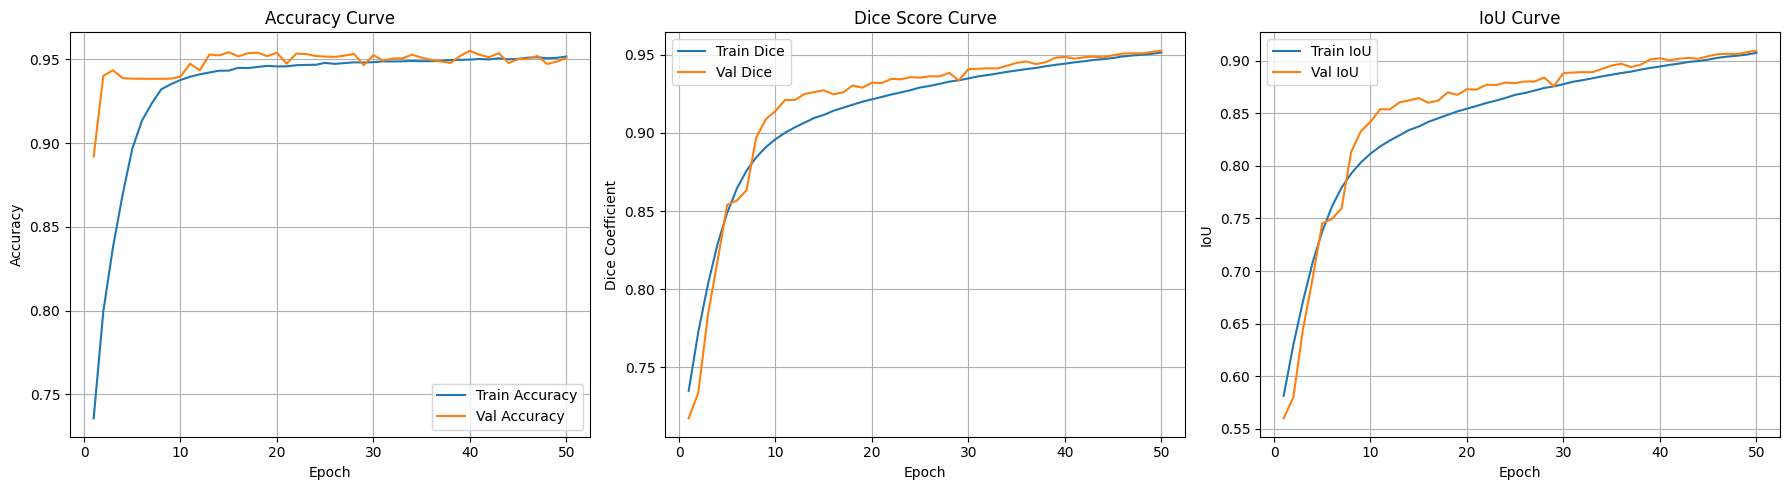

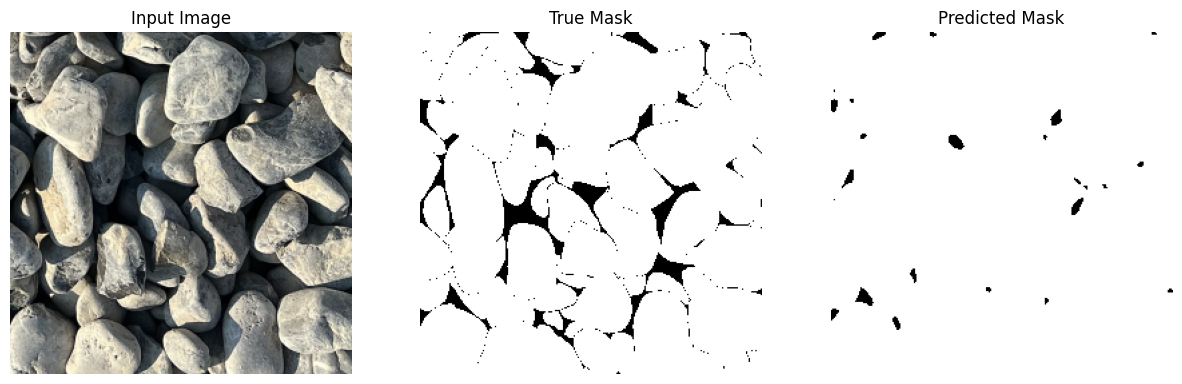

In [3]:
def dice_coef(y_true, y_pred, smooth=1e-7):
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2.0 * intersection + smooth) / (
        tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth
    )

def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)

def iou_coef(y_true, y_pred, smooth=1e-7):
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)

def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv2D(filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    return x

def down_block(x, filters):
    c = conv_block(x, filters)
    p = layers.MaxPool2D((2, 2))(c)
    p = layers.Dropout(0.2)(p)
    return c, p

def up_block(x, skip, filters):
    x = layers.Conv2DTranspose(filters, 2, strides=2, padding="same")(x)
    x = layers.Concatenate()([x, skip])
    x = layers.Dropout(0.2)(x)
    x = conv_block(x, filters)
    return x

def build_unet(input_shape=(256, 256, 3)):
    inputs = layers.Input(shape=input_shape)

    s1, p1 = down_block(inputs, 32)
    s2, p2 = down_block(p1, 64)
    s3, p3 = down_block(p2, 128)
    s4, p4 = down_block(p3, 256)

    bottleneck = conv_block(p4, 512)

    u1 = up_block(bottleneck, s4, 256)
    u2 = up_block(u1, s3, 128)
    u3 = up_block(u2, s2, 64)
    u4 = up_block(u3, s1, 32)

    outputs = layers.Conv2D(1, 1, activation="sigmoid")(u4)

    model = Model(inputs, outputs, name="UNet_Binary")
    return model

model = build_unet()
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=dice_loss,
    metrics=["accuracy", dice_coef, iou_coef]
)

model.summary()

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        os.path.join(OUTPUT_DIR, "best_unet.keras"),
        monitor="val_dice_coef",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_dice_coef",
        mode="max",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_dice_coef",
        mode="max",
        factor=0.5,
        patience=4,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

def plot_training_curves(history):
    hist = history.history
    epochs_range = range(1, len(hist["loss"]) + 1)

    plt.figure(figsize=(18, 5))

    plt.subplot(1, 3, 1)
    plt.plot(epochs_range, hist["accuracy"], label="Train Accuracy")
    plt.plot(epochs_range, hist["val_accuracy"], label="Val Accuracy")
    plt.title("Accuracy Curve")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 3, 2)
    plt.plot(epochs_range, hist["dice_coef"], label="Train Dice")
    plt.plot(epochs_range, hist["val_dice_coef"], label="Val Dice")
    plt.title("Dice Score Curve")
    plt.xlabel("Epoch")
    plt.ylabel("Dice Coefficient")
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 3, 3)
    plt.plot(epochs_range, hist["iou_coef"], label="Train IoU")
    plt.plot(epochs_range, hist["val_iou_coef"], label="Val IoU")
    plt.title("IoU Curve")
    plt.xlabel("Epoch")
    plt.ylabel("IoU")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

plot_training_curves(history)

def show_prediction(model, pair):
    img_path, mask_path = pair
    img, mask = load_image_mask(img_path.encode(), mask_path.encode())

    pred = model.predict(np.expand_dims(img, axis=0), verbose=0)[0]
    pred_mask = (pred > 0.5).astype(np.uint8)

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(img)
    plt.title("Input Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(mask.squeeze(), cmap="gray")
    plt.title("True Mask")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(pred_mask.squeeze(), cmap="gray")
    plt.title("Predicted Mask")
    plt.axis("off")

    plt.show()

show_prediction(model, val_pairs[0])


Loaded best validation-selected checkpoint: /raid/home/dgx1725/unet_aspect10_baseline_outputs/best_unet.keras
Prediction threshold: 0.5
Boundary tolerance: 2 pixels
Validation image 1/3: Agg_Rounded_Black_M_HLC_03.jpg
Validation image 2/3: Agg_Crushed_Clear_M_GLC_03.jpg
Validation image 3/3: Agg_Crushed_Red_S_GLC_03.jpg

VALIDATION METRICS — MACRO-AVERAGE OVER 3 IMAGES
IoU                     : 0.9499 ± 0.0184
Recall                  : 0.9954 ± 0.0060
Precision               : 0.9542 ± 0.0180
Dice Coefficient        : 0.9743 ± 0.0096
Boundary F1             : 0.5462 ± 0.1220
Boundary Recall         : 0.3862 ± 0.1225
Boundary Precision      : 0.9747 ± 0.0169
Saved per-image metrics: /raid/home/dgx1725/unet_aspect10_baseline_outputs/validation_metrics_per_image.csv
Saved summary metrics : /raid/home/dgx1725/unet_aspect10_baseline_outputs/validation_metrics_summary.csv


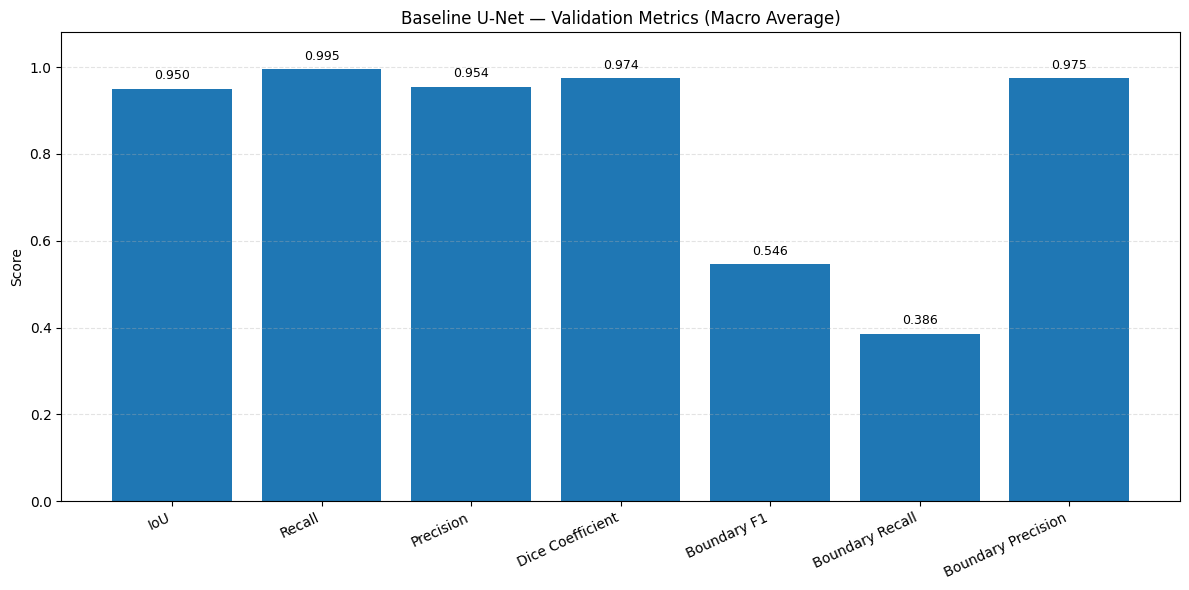

Saved macro-average plot: /raid/home/dgx1725/unet_aspect10_baseline_outputs/validation_metrics_macro_average.png


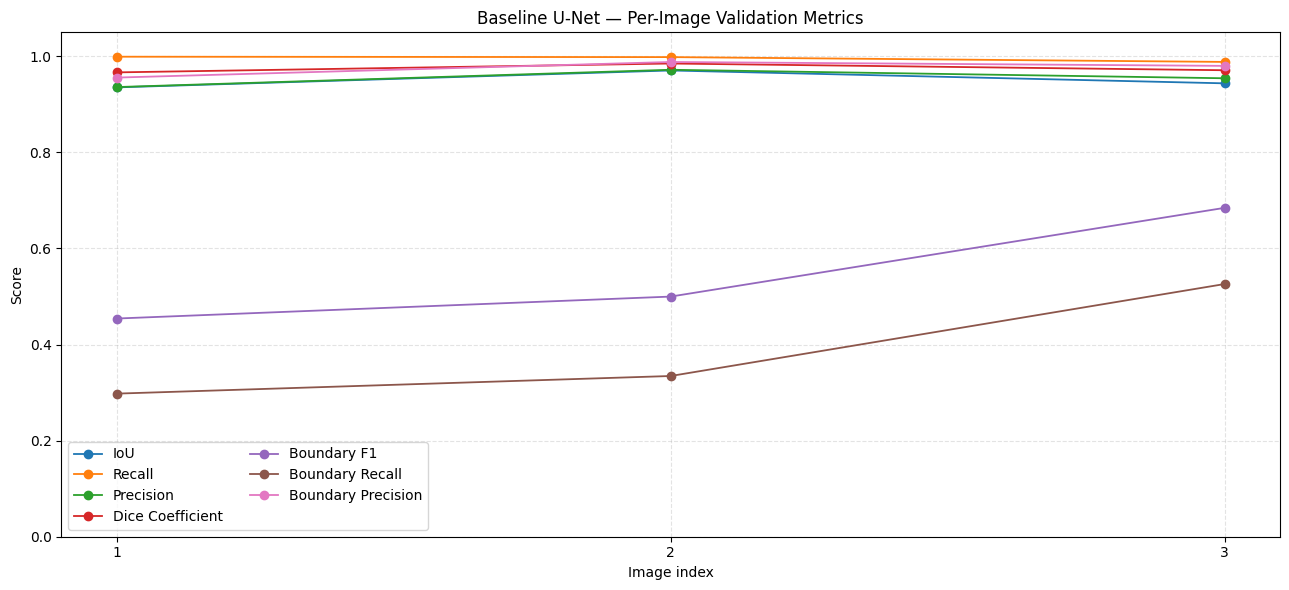

Saved per-image plot: /raid/home/dgx1725/unet_aspect10_baseline_outputs/validation_metrics_per_image.png
Test image 1/3: LightAgg_Black_M_HTC_01.jpg
Test image 2/3: Agg_Crushed_Red_S_GLC_01.jpg
Test image 3/3: Agg_Crushed_Green_M_GLC_01.jpg

TEST METRICS — MACRO-AVERAGE OVER 3 IMAGES
IoU                     : 0.9585 ± 0.0158
Recall                  : 0.9953 ± 0.0032
Precision               : 0.9629 ± 0.0174
Dice Coefficient        : 0.9788 ± 0.0082
Boundary F1             : 0.6466 ± 0.1075
Boundary Recall         : 0.4883 ± 0.1158
Boundary Precision      : 0.9795 ± 0.0122
Saved per-image metrics: /raid/home/dgx1725/unet_aspect10_baseline_outputs/test_metrics_per_image.csv
Saved summary metrics : /raid/home/dgx1725/unet_aspect10_baseline_outputs/test_metrics_summary.csv


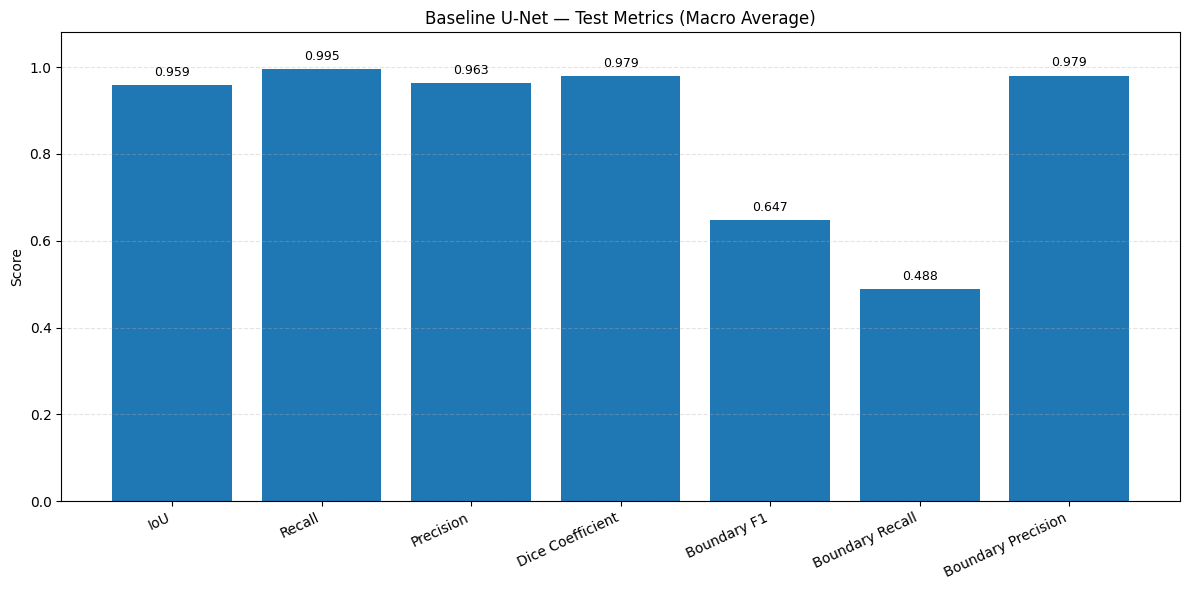

Saved macro-average plot: /raid/home/dgx1725/unet_aspect10_baseline_outputs/test_metrics_macro_average.png


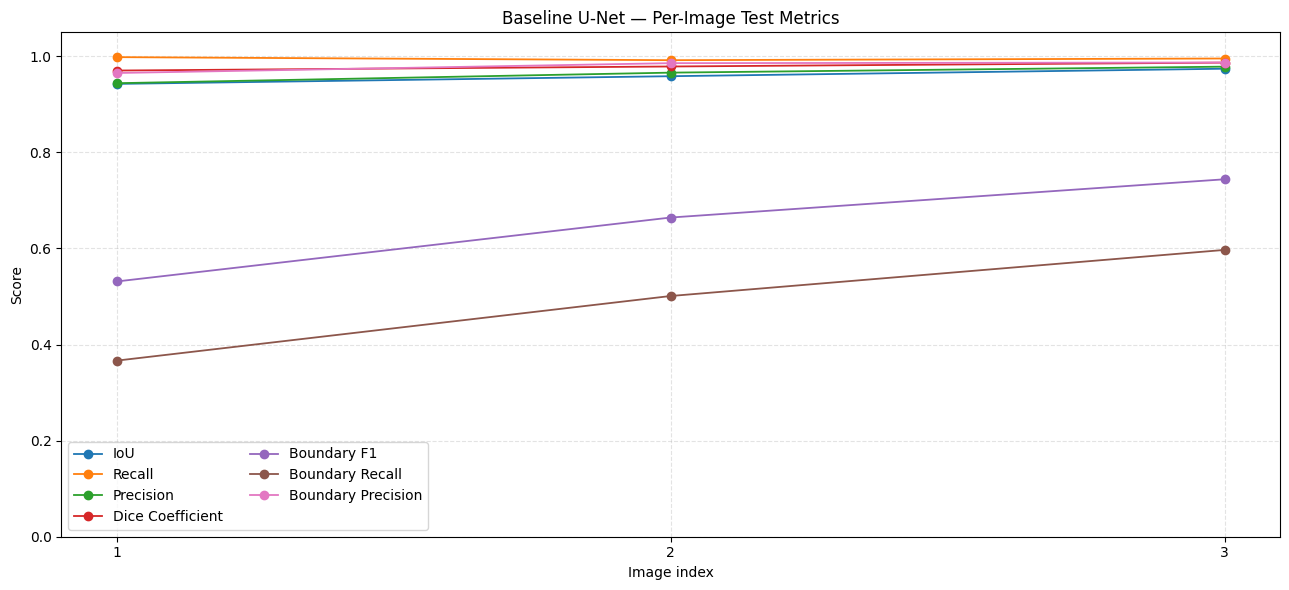

Saved per-image plot: /raid/home/dgx1725/unet_aspect10_baseline_outputs/test_metrics_per_image.png

TEST EVALUATION COMPLETE. Report the TEST summary as final held-out performance;
keep the validation summary separate, and do not describe old validation scores as test results.


In [4]:
BEST_MODEL_PATH = os.path.join(OUTPUT_DIR, "best_unet.keras")
if not os.path.isfile(BEST_MODEL_PATH):
    raise FileNotFoundError(
        f"Best checkpoint not found: {BEST_MODEL_PATH}. Run the notebook from the start "
        "so training creates the checkpoint before evaluation."
    )

_custom_objects = {name: globals()[name] for name in ("FixedKernelLayer", "LearnableDepthwiseConv2D") if name in globals()}
best_model = tf.keras.models.load_model(
    BEST_MODEL_PATH, custom_objects=_custom_objects, compile=False
)
print("Loaded best validation-selected checkpoint:", BEST_MODEL_PATH)
print("Prediction threshold:", PRED_THRESHOLD)
print("Boundary tolerance:", BOUNDARY_TOLERANCE, "pixels")

METRIC_NAMES = [
    "iou", "recall", "precision", "dice_coef",
    "boundary_f1", "boundary_recall", "boundary_precision",
]
DISPLAY_NAMES = {
    "iou": "IoU",
    "recall": "Recall",
    "precision": "Precision",
    "dice_coef": "Dice Coefficient",
    "boundary_f1": "Boundary F1",
    "boundary_recall": "Boundary Recall",
    "boundary_precision": "Boundary Precision",
}

def _extract_boundary(mask):
    mask = (np.asarray(mask).squeeze() > 0).astype(np.uint8)
    eroded = cv2.erode(
        mask,
        np.ones((3, 3), dtype=np.uint8),
        iterations=1,
        borderType=cv2.BORDER_CONSTANT,
        borderValue=0,
    )
    return (mask - eroded).astype(np.uint8)

def _segmentation_metrics(gt_mask, pred_mask, tolerance=2):
    gt = (np.asarray(gt_mask).squeeze() > 0.5).astype(np.uint8)
    pred = (np.asarray(pred_mask).squeeze() > 0).astype(np.uint8)
    if gt.shape != pred.shape:
        raise ValueError(f"Mask shape mismatch: GT={gt.shape}, prediction={pred.shape}")

    tp = int(np.sum((gt == 1) & (pred == 1)))
    fp = int(np.sum((gt == 0) & (pred == 1)))
    fn = int(np.sum((gt == 1) & (pred == 0)))
    precision = tp / (tp + fp) if (tp + fp) else (1.0 if (tp + fn) == 0 else 0.0)
    recall = tp / (tp + fn) if (tp + fn) else (1.0 if (tp + fp) == 0 else 0.0)
    dice_den = 2 * tp + fp + fn
    dice = (2 * tp / dice_den) if dice_den else 1.0
    iou_den = tp + fp + fn
    iou = tp / iou_den if iou_den else 1.0

    gt_boundary = _extract_boundary(gt)
    pred_boundary = _extract_boundary(pred)
    gt_count, pred_count = int(gt_boundary.sum()), int(pred_boundary.sum())
    tolerance = max(0, int(tolerance))
    if tolerance:
        kernel_size = 2 * tolerance + 1
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel_size, kernel_size))
        gt_dilated = cv2.dilate(gt_boundary, kernel, iterations=1)
        pred_dilated = cv2.dilate(pred_boundary, kernel, iterations=1)
    else:
        gt_dilated, pred_dilated = gt_boundary, pred_boundary

    matched_pred = int(np.sum((pred_boundary > 0) & (gt_dilated > 0)))
    matched_gt = int(np.sum((gt_boundary > 0) & (pred_dilated > 0)))
    boundary_precision = (
        matched_pred / pred_count if pred_count else (1.0 if gt_count == 0 else 0.0)
    )
    boundary_recall = (
        matched_gt / gt_count if gt_count else (1.0 if pred_count == 0 else 0.0)
    )
    boundary_sum = boundary_precision + boundary_recall
    boundary_f1 = 2 * boundary_precision * boundary_recall / boundary_sum if boundary_sum else 0.0

    return {
        "iou": float(iou),
        "recall": float(recall),
        "precision": float(precision),
        "dice_coef": float(dice),
        "boundary_f1": float(boundary_f1),
        "boundary_recall": float(boundary_recall),
        "boundary_precision": float(boundary_precision),
    }

def evaluate_split(split_pairs, split_name, save_prediction_masks=False):
    if not split_pairs:
        raise ValueError(f"The {split_name} split is empty.")
    rows = []
    prediction_dir = os.path.join(OUTPUT_DIR, "test_predictions")
    if save_prediction_masks:
        os.makedirs(prediction_dir, exist_ok=True)

    for idx, (image_path, mask_path) in enumerate(split_pairs, start=1):
        image, gt_mask = load_image_mask(os.fsencode(image_path), os.fsencode(mask_path))
        pred_prob = best_model.predict(np.expand_dims(image, axis=0), verbose=0)[0]
        pred_mask = (np.asarray(pred_prob).squeeze() >= PRED_THRESHOLD).astype(np.uint8)
        gt_binary = (np.asarray(gt_mask).squeeze() > 0.5).astype(np.uint8)
        scores = _segmentation_metrics(gt_binary, pred_mask, BOUNDARY_TOLERANCE)
        rows.append({"image": os.path.basename(image_path), **scores})

        if save_prediction_masks:
            out_name = os.path.splitext(os.path.basename(image_path))[0] + "_pred.png"
            cv2.imwrite(os.path.join(prediction_dir, out_name), pred_mask * 255)
        print(f"{split_name.title()} image {idx}/{len(split_pairs)}: {os.path.basename(image_path)}")

    results_df = pd.DataFrame(rows)
    means = results_df[METRIC_NAMES].mean()
    stds = results_df[METRIC_NAMES].std(ddof=1).fillna(0.0) if len(results_df) > 1 else means * 0.0

    print("\n" + "=" * 68)
    print(f"{split_name.upper()} METRICS — MACRO-AVERAGE OVER {len(results_df)} IMAGES")
    print("=" * 68)
    for metric in METRIC_NAMES:
        print(f"{DISPLAY_NAMES[metric]:<24}: {means[metric]:.4f} ± {stds[metric]:.4f}")
    print("=" * 68)

    summary_df = pd.DataFrame({
        "metric": [DISPLAY_NAMES[m] for m in METRIC_NAMES],
        "mean_score": [float(means[m]) for m in METRIC_NAMES],
        "std_score": [float(stds[m]) for m in METRIC_NAMES],
        "n_images": [len(results_df)] * len(METRIC_NAMES),
    })
    per_image_csv = os.path.join(OUTPUT_DIR, f"{split_name}_metrics_per_image.csv")
    summary_csv = os.path.join(OUTPUT_DIR, f"{split_name}_metrics_summary.csv")
    results_df.to_csv(per_image_csv, index=False)
    summary_df.to_csv(summary_csv, index=False)
    print("Saved per-image metrics:", per_image_csv)
    print("Saved summary metrics :", summary_csv)

    values = [float(means[m]) for m in METRIC_NAMES]
    labels = [DISPLAY_NAMES[m] for m in METRIC_NAMES]
    plt.figure(figsize=(12, 6))
    bars = plt.bar(labels, values)
    plt.ylim(0, 1.08)
    plt.ylabel("Score")
    plt.title(f"Baseline U-Net — {split_name.title()} Metrics (Macro Average)")
    plt.xticks(rotation=25, ha="right")
    plt.grid(axis="y", linestyle="--", alpha=0.35)
    for bar, value in zip(bars, values):
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.015,
                 f"{value:.3f}", ha="center", va="bottom", fontsize=9)
    plt.tight_layout()
    macro_plot = os.path.join(OUTPUT_DIR, f"{split_name}_metrics_macro_average.png")
    plt.savefig(macro_plot, dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved macro-average plot:", macro_plot)

    image_numbers = np.arange(1, len(results_df) + 1)
    plt.figure(figsize=(13, 6))
    for metric in METRIC_NAMES:
        plt.plot(image_numbers, results_df[metric], marker="o", linewidth=1.3,
                 label=DISPLAY_NAMES[metric])
    plt.ylim(0, 1.05)
    plt.xlabel("Image index")
    plt.ylabel("Score")
    plt.title(f"Baseline U-Net — Per-Image {split_name.title()} Metrics")
    plt.xticks(image_numbers)
    plt.grid(True, linestyle="--", alpha=0.35)
    plt.legend(ncol=2)
    plt.tight_layout()
    per_image_plot = os.path.join(OUTPUT_DIR, f"{split_name}_metrics_per_image.png")
    plt.savefig(per_image_plot, dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved per-image plot:", per_image_plot)
    return results_df, summary_df

if "load_image_mask" not in globals():
    raise RuntimeError("load_image_mask() is not defined. Run the data-loading cells first.")
if "val_pairs" not in globals() or "test_pairs" not in globals():
    raise RuntimeError("val_pairs/test_pairs not found. Run the split cell and retrain first.")

validation_results, validation_summary = evaluate_split(
    val_pairs, "validation", save_prediction_masks=False
)

test_results, test_summary = evaluate_split(
    test_pairs, "test", save_prediction_masks=True
)
print("\nTEST EVALUATION COMPLETE. Report the TEST summary as final held-out performance;")
print("keep the validation summary separate, and do not describe old validation scores as test results.")
